# Laboratorio 10: Redes neuronales con Keras

**Mateo Caballero** - Aprendizaje Estadístico - semestre 2026-2

Enunciado original: `semestre2026-2/Laboratorios/Laboratorio_10_nn_keras__V1.ipynb`

El notebook conserva el enunciado completo y en su orden:

- **Primera parte (material de la sesión).** Funciones de activación, tres formas de definir capas en
  Keras y el ejemplo de los círculos. Se ejecuta el código del enunciado y se añaden observaciones y
  celdas `# [Añadido]`, entre ellas la modificación de los parámetros de las activaciones que pide la
  celda de gráficas. El código del enunciado se ejecuta tal cual, salvo `verbose=1` → `verbose=0` en el
  ejemplo de los círculos (con 1 000 épocas, `verbose=1` imprime 1 000 líneas de progreso). Se omiten
  una celda de código vacía y el botón "Open in Colab", que abre el notebook original del profesor.
- **Segunda parte (Laboratorio).** Los dos puntos pedidos: una red para `make_moons` (punto 1) y una red
  para `load_digits` (punto 2), más una extensión con los 10 dígitos.

**Entorno.** Python 3.14, TensorFlow 2.22.0rc0 y Keras 3.15.1. La primera celda añadida silencia
dos avisos que provoca el código del enunciado (se explican en esa celda), porque repetirían en cada
salida la ruta local de este equipo. TensorFlow solo publica una versión
preliminar (*release candidate*) para Python 3.14. El código usa `from tensorflow import keras` como el
enunciado y corre igual en Colab con la versión estable.



| Función de activación | Ventajas | Desventajas |
| --------------------- | -------- | ----------- |
| Lineal | Simple y rápida de calcular | Le falta introducir no linealidad, no limita el rango de salida |
| Sigmoide | Mapea la salida al rango (0, 1), útil para clasificación binaria | Se satura fácilmente, tiene gradientes pequeños, no tiene media cero |
| Tangente hiperbólica | Mapea la salida al rango (-1, 1), tiene media cero, es más fuerte que la sigmoide | Se satura fácilmente, tiene gradientes pequeños |
| ReLU | Introduce no linealidad, tiene gradientes grandes, es rápida de calcular | Puede morir si la entrada es negativa, no tiene media cero |


# Keras: https://keras.io/api/layers/activations/

Keras es una bilbioteca con librerias de código abierto para entrenar modelos de deep learning DL que puede ejecutarse en TensorFlow. Keras permite construir bloque de arquitectura de la redes neuronales, y permite construir desde un perceptron hasta redes neuronales convolucionales  y recurrentes de una manera amigable con el usuario.


# Funciones de activación

Tipos de funciones de activación:

## Lineal:

Una transformación lineal, la cual se muestra en la siguiente figura, consiste básicamente, en la función identidad. En estra transformación, la variable dependiente tiene una relación directa y proporcional con la variable independiente. En términos prácticos, lo anterior significa que una función de activación lineal pasa la señal sin realizar un cambio sobre esta. Este el típo de activación que se usa en la capa de entrada de las redes neuronales.


## Sigmoide:
Como todas las transformaciones logísticas, las sigmoides puede reducir la cantidad de valores extremos o outliers en los datos sin eliminarlos. En la siguiente figura se ilustra dicha función sigmoide:

Una función sigmoide convierde una variable independiente de rango infinito en probabilidades con un rango entre 0 y 1. La mayoria de las salidas serán cercanas a 0 o 1, que corresponden a zonas de saturación.

La función de activación sigmoide devuelve una probabilidad independiente para cada clase.



##  Tanh
Corresponde a una función trigonométrica hiperbólica donde el rango de salida de tanh varía entre -1 y 1, note la diferencia con la función sigmoide. La ventaja de tanh es puede tratar los números negativos de forma más eficiente que la función sigmoide.


## ReLU: Rectified Linear Unit (Unidad Rectificadad Lineal)
La unidad rectificada lineal es una trasformación más intersante que activa un nodo solo si la entrada se encuentra por encima de cierta cantidad. Si la entrada está por debajo de zero, la salida es cero, pero si la entrada alcanza un valor umbral, la salida tiene una relación lineal con la variable dependiente.

Las funciones de activaciones ReLU representan actualmente el estado de arte en la aplicación de funciones de activación, ya que han demostrado un buen desempeño en diferentes situaciones. Dado que el gradiente de la ReLU es cero o constante, permite evitar el problema del desvanecimiento del gradiente. Las funciones de activación ReLu han demostrado un mejor entrenamiento en la práctica que las funciones de activación sigmoidea.

Las funciones de activación ReLU se usan, normalmente, en las capas ocultas.

Existen mas funciones de activación, no obstante, nos centraremos a continuación solo en una más. Esta función de activación es usada en la capa de salida de la clasificación multiclase mediante una red neuronal. Es conocida como Softmax.


## Softmax
La función de activación Softmax representa una generalización de la regresión logística en el sentido que puede ser apllicada a un conjunto continuos de datos (en lugar de una clasificación binaria) y puede contener múltiples fronteras de desición. Esta función maneja sistemas multinomiales para el etiquetado. Softmax es una función que normalmente se usa en la capa de salida de un clasificador.

La función de activación Softmax devuelve la distribución de probablilidades de clases mutuamente excluyentes.

Consideremos el siguiente ejemplo en donde se ilustra, entre otra cosas la definición de la función SoftMax:

$S(y_i)=\frac{e^y_i}{\sum e^{y_i}}$


En deep learning, el térno capa logit se usa para la última capa de neuronas de la red neuronal para el problema de clasificación que produce unos valores de predicción "crudos" de valores reales que varian en el intervalo . En concreto, las cantidades logits son los puntajes crudos de la ultima capa de la red neuronal, antes de que se les aplique la activación.


Ref: https://github.com/ssanchezgoe/curso_deep_learning_economia/blob/main/NBs_Google_Colab/DL_S07_Funciones_Activacion_Arquitectura_Red.ipynb

In [1]:
# [Añadido]
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # oculta los registros internos de C++ de TensorFlow (antes de importarlo)
import tensorflow as tf
tf.config.experimental.enable_op_determinism()   # con la misma semilla, la misma ejecución da los mismos números
SEED = 42

import warnings
# Dos avisos que el código del enunciado provoca y que repetirían la ruta local en cada salida:
# Keras 3 desaconseja pasar input_shape a la primera capa, y TensorFlow avisa de que
# reset_default_graph está obsoleto cuando se llama a keras.backend.clear_session().
warnings.filterwarnings("ignore", message=".*input_shape.*")
tf.get_logger().addFilter(lambda registro: "reset_default_graph" not in registro.getMessage())

In [2]:
import numpy as np
from tensorflow import keras


In [3]:
# 1: A través de una capa medidante el método Activación:
modelA = keras.models.Sequential()
modelA.add(keras.layers.Dense(32, input_shape=(16,)))
modelA.add(keras.layers.Activation('relu'))#  Capa activación
modelA.add(keras.layers.Dense(64))
modelA.add(keras.layers.Activation('tanh'))#  Capa activación
modelA.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,656 (10.38 KB)

 Trainable params: 2,656 (10.38 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# 2: Mediante el argumento activation
modelB = keras.models.Sequential()
modelB.add(keras.layers.Dense(32, input_shape=(16,)))
modelA.add(keras.layers.Activation('relu'))#  Capa activación
modelB.add(keras.layers.Dense(64, activation='tanh'))
modelB.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,656 (10.38 KB)

 Trainable params: 2,656 (10.38 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
# 3: Mediante una función de Tensor-flow por elementos.
modelC = keras.models.Sequential()
modelC.add(keras.layers.Dense(32, activation='relu', input_shape=(16,)))
modelC.add(keras.layers.Dense(64, activation='tanh'))
modelC.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         2,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,656 (10.38 KB)

 Trainable params: 2,656 (10.38 KB)

 Non-trainable params: 0 (0.00 B)

**Observaciones sobre las tres formas de definir la red.**

Las tres celdas pretenden construir la misma red, 16 → 32 (relu) → 64 (tanh), cambiando solo la manera
de declarar las activaciones. Las tres tienen 2 656 parámetros:
$(16\cdot32 + 32) + (32\cdot64 + 64) = 544 + 2\,112$. Las capas `Activation` no tienen parámetros.

**La celda de la forma 2 tiene un error.** La línea `modelA.add(keras.layers.Activation('relu'))` agrega
la activación al modelo A en lugar del B. Las celdas siguientes lo comprueban:

- `modelA` termina con una tercera capa `Activation` (relu después de tanh), que anula las salidas
  negativas de la tanh.
- `modelB` queda sin activación después de su primera capa densa, que se vuelve lineal. El error no
  se nota en `modelB.summary()`, porque el resumen no muestra las activaciones pasadas como argumento.
- Escritas correctamente, la forma 1 (capa `Activation`) y la forma 2 (argumento `activation`) dan la
  misma salida que la forma 3 cuando se les copian los mismos pesos. El `modelB` del enunciado da una
  salida distinta.

Keras 3 advierte que ya no se recomienda pasar `input_shape` a la primera capa; en su lugar se usa
`keras.Input(shape=...)`, como en el código añadido. Ese aviso es el que silencia la primera celda.

In [6]:
# [Añadido]
# Parámetros de cada capa: Dense(n_in -> n_out) tiene n_in*n_out + n_out; Activation no tiene parámetros
for nombre, m in [("modelA", modelA), ("modelB", modelB), ("modelC", modelC)]:
    print(f"{nombre}: {[(capa.__class__.__name__, capa.count_params()) for capa in m.layers]}  total = {m.count_params()}")
print("A mano: (16*32 + 32) + (32*64 + 64) =", 16 * 32 + 32 + 32 * 64 + 64)

modelA: [('Dense', 544), ('Activation', 0), ('Dense', 2112), ('Activation', 0), ('Activation', 0)]  total = 2656
modelB: [('Dense', 544), ('Dense', 2112)]  total = 2656
modelC: [('Dense', 544), ('Dense', 2112)]  total = 2656
A mano: (16*32 + 32) + (32*64 + 64) = 2656


In [7]:
# [Añadido]
# Definidas correctamente, las formas 1 y 2 son la misma red que la 3: con los mismos pesos dan la misma salida
modelA_ok = keras.models.Sequential([keras.Input(shape=(16,)), keras.layers.Dense(32), keras.layers.Activation("relu"),
                                     keras.layers.Dense(64), keras.layers.Activation("tanh")])
modelB_ok = keras.models.Sequential([keras.Input(shape=(16,)), keras.layers.Dense(32, activation="relu"),
                                     keras.layers.Dense(64, activation="tanh")])
x_prueba = np.random.default_rng(0).normal(size=(5, 16)).astype("float32")
for nombre, m in [("forma 1 (Activation)", modelA_ok), ("forma 2 (argumento activation)", modelB_ok)]:
    m.set_weights(modelC.get_weights())
    print(f"{nombre:32s} misma salida que modelC: {np.allclose(m(x_prueba), modelC(x_prueba))}")
# El modelB del enunciado (sin relu tras la primera capa) da otra salida con los mismos pesos
modelB.set_weights(modelC.get_weights())   # sus pesos tienen las mismas formas que los de modelC
print(f"{'modelB del enunciado':32s} misma salida que modelC: {np.allclose(modelB(x_prueba), modelC(x_prueba))}")

forma 1 (Activation)             misma salida que modelC: True
forma 2 (argumento activation)   misma salida que modelC: True
modelB del enunciado             misma salida que modelC: False


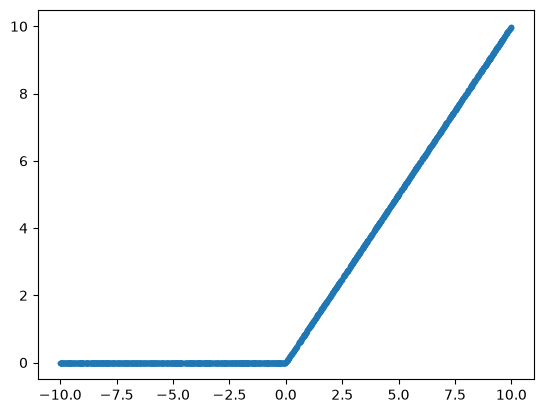

In [8]:
# Vamos a graficar las funciones de activación y modificar los parámetros que las definen
# Encuentran los parámetros en https://keras.io/api/layers/activations/
# Relu
import matplotlib.pyplot as plt
x=np.random.uniform(low=-10.0, high=10, size=(2000,))
y=keras.activations.relu(x, negative_slope=0, max_value=None, threshold=0)
plt.plot(x,y,'.')

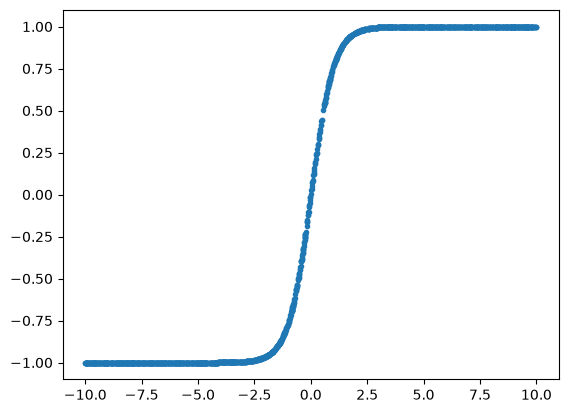

In [9]:
# tanh
y=keras.activations.tanh(x)
plt.plot(x,y,'.')

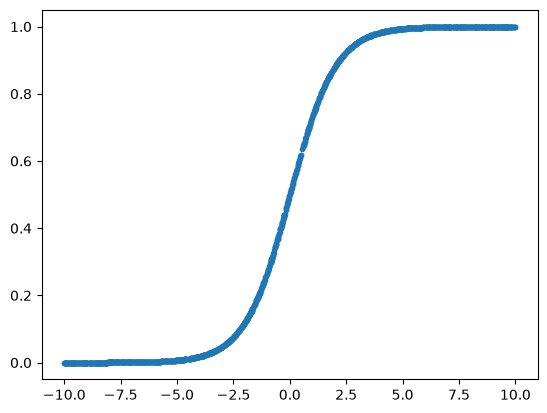

In [10]:
#sigmoid
y=keras.activations.sigmoid(x)
plt.plot(x,y,'.')

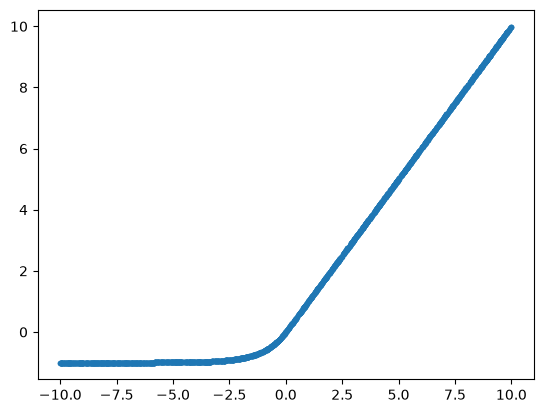

In [11]:
# elu
y=keras.activations.elu(x, alpha=1.0)
plt.plot(x,y,'.')

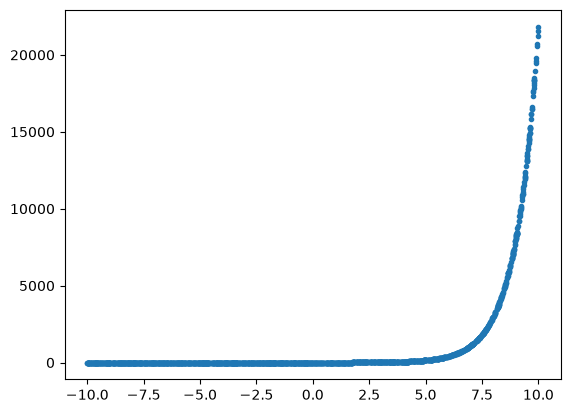

In [12]:
# Exponential
y=keras.activations.exponential(x)
plt.plot(x,y,'.')

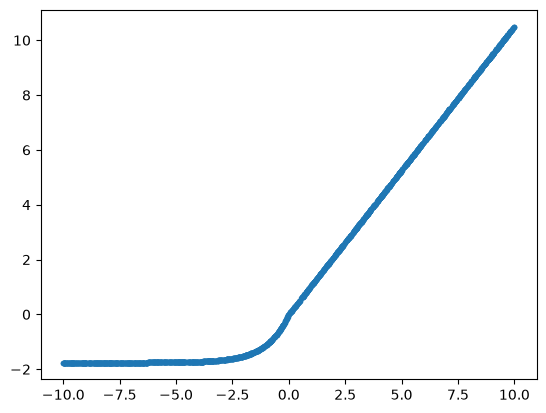

In [13]:
# Selu
y=keras.activations.selu(x)
plt.plot(x,y,'.')

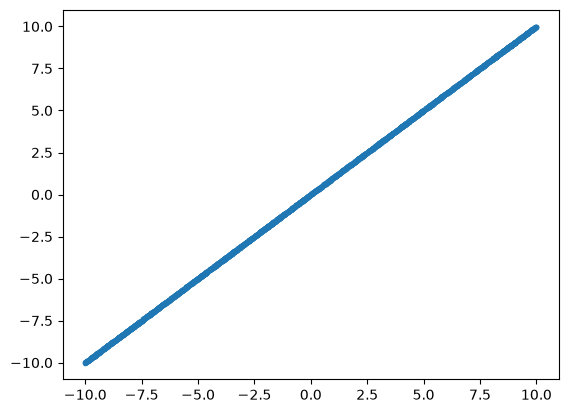

In [14]:
# Linear
y=keras.activations.linear(x)
plt.plot(x,y,'.')

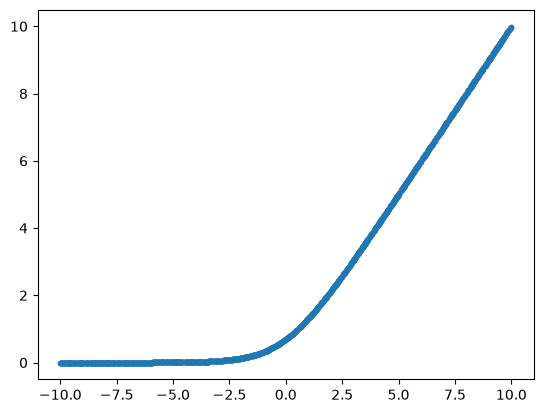

In [15]:
y=keras.activations.softplus(x)
plt.plot(x,y,'.')


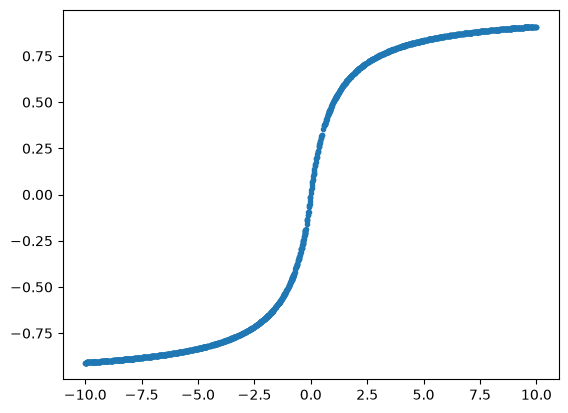

In [16]:
y=keras.activations.softsign(x)
plt.plot(x,y,'.')

**Modificación de los parámetros de las activaciones.** La celda de las gráficas pide variar los
parámetros que definen cada función (https://keras.io/api/layers/activations/):

- **`relu(negative_slope=0.1)`**: la parte negativa ya no es cero sino $0.1z$ (por ejemplo,
  $-3 \to -0.3$). Es la *leaky ReLU*: el gradiente no se anula para $z<0$, lo que evita las neuronas
  "muertas" que menciona la tabla de desventajas.
- **`relu(max_value=6)`**: recorta la salida en 6 ($10 \to 6$). Acota el rango de la activación.
- **`relu(threshold=2)`**: anula todo valor por debajo de 2 ($1.5 \to 0$) y deja pasar los demás sin
  cambio ($3 \to 3$), con un salto en $z = 2$.
- **`elu(alpha)`**: para $z<0$ vale $\alpha(e^z - 1)$, que tiende a $-\alpha$. Con $\alpha = 2$,
  $-3 \to 2(e^{-3}-1) = -1.9004$. A diferencia de relu, es suave y toma valores negativos.
- **`selu`** es una elu con constantes fijas: la celda comprueba que `selu(z)` coincide con
  `1.0507 * elu(z, alpha=1.6733)`.

**Softmax.** Los logits $[2, 1, 0.1]$ se convierten en las probabilidades $[0.659, 0.2424, 0.0986]$,
que suman 1 y coinciden con el cálculo a mano $e^{z_i}/\sum_j e^{z_j}$. Con dos clases,
$\mathrm{softmax}([z, 0])_0 = \sigma(z)$: la sigmoide de salida en clasificación binaria (punto 1) es el
caso de dos clases de la softmax que se usa en el problema multiclase (punto 2).

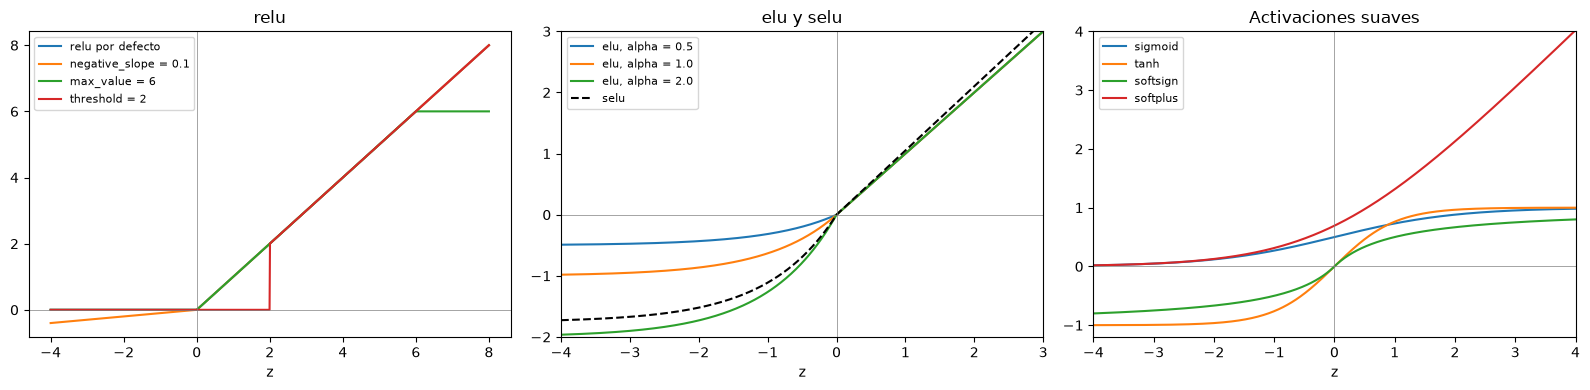

z                          [-3.  -1.   0.5  1.5  3.  10. ]
relu, negative_slope = 0.1  [-0.3 -0.1  0.5  1.5  3.  10. ]
relu, max_value = 6         [0.  0.  0.5 1.5 3.  6. ]
relu, threshold = 2         [ 0.  0.  0.  0.  3. 10.]
elu, alpha = 2              [-1.9004 -1.2642  0.5     1.5     3.     10.    ]
selu(z) == 1.0507 * elu(z, alpha=1.6733): True


In [17]:
# [Añadido]
# Modificación de los parámetros de las activaciones (documentación: https://keras.io/api/layers/activations/)
xs = np.linspace(-4, 8, 1000)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for kw, etiqueta in [({}, "relu por defecto"), ({"negative_slope": 0.1}, "negative_slope = 0.1"),
                     ({"max_value": 6}, "max_value = 6"), ({"threshold": 2}, "threshold = 2")]:
    axes[0].plot(xs, keras.activations.relu(xs, **kw), label=etiqueta)
axes[0].set(title="relu", xlabel="z")
for a in [0.5, 1.0, 2.0]:
    axes[1].plot(xs, keras.activations.elu(xs, alpha=a), label=f"elu, alpha = {a}")
axes[1].plot(xs, keras.activations.selu(xs), "k--", label="selu")
axes[1].set(title="elu y selu", xlabel="z", xlim=(-4, 3), ylim=(-2, 3))
for nombre in ["sigmoid", "tanh", "softsign", "softplus"]:
    axes[2].plot(xs, getattr(keras.activations, nombre)(xs), label=nombre)
axes[2].set(title="Activaciones suaves", xlabel="z", xlim=(-4, 4), ylim=(-1.2, 4))
for ax in axes:
    ax.axhline(0, color="gray", lw=0.5); ax.axvline(0, color="gray", lw=0.5); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Comprobaciones numéricas de los parámetros
z = np.array([-3.0, -1.0, 0.5, 1.5, 3.0, 10.0])
print("z                         ", z)
print("relu, negative_slope = 0.1 ", np.asarray(keras.activations.relu(z, negative_slope=0.1)))
print("relu, max_value = 6        ", np.asarray(keras.activations.relu(z, max_value=6)))
print("relu, threshold = 2        ", np.asarray(keras.activations.relu(z, threshold=2)))
print("elu, alpha = 2             ", np.asarray(keras.activations.elu(z, alpha=2.0)).round(4))

# selu es una elu con constantes fijas: escala * elu(z, alpha)
escala_selu, alfa_selu = 1.0507009873554805, 1.6732632423543772
print("selu(z) == 1.0507 * elu(z, alpha=1.6733):",
      np.allclose(np.asarray(keras.activations.selu(z)),
                  escala_selu * np.asarray(keras.activations.elu(z, alpha=alfa_selu))))

In [18]:
# [Añadido]
# Softmax: convierte puntajes (logits) en probabilidades que suman 1
logits = np.array([[2.0, 1.0, 0.1]])
p = np.asarray(keras.activations.softmax(logits))
print("logits:", logits[0], "-> softmax:", p[0].round(4), "| suma =", p.sum())
print("a mano:", (np.exp(logits) / np.exp(logits).sum()).round(4)[0])
# Con dos clases, softmax([z, 0]) coincide con sigmoid(z)
zz = np.array([-2.0, 0.0, 1.5])
print("softmax([z, 0])[0]:", np.asarray(keras.activations.softmax(np.c_[zz, np.zeros(3)]))[:, 0].round(4),
      "  sigmoid(z):", np.asarray(keras.activations.sigmoid(zz)).round(4))

logits: [2.  1.  0.1] -> softmax: [0.659  0.2424 0.0986] | suma = 1.0
a mano: [0.659  0.2424 0.0986]
softmax([z, 0])[0]: [0.1192 0.5    0.8176]   sigmoid(z): [0.1192 0.5    0.8176]


# Arquitectura y funcionalidad de la Redes neuronales secuenciales:

De las funciones de activación habladas en la clase anterior podemos advertir dos características que deben poseer una red neuronal:

Las funciones de activación de las capas ocultas deben ser funciones de activación no lineales, con el fín de que la red actue como un aproximador universal a una función.

La función de activación de la capa de salida determina el tipo de clasificación/regresión del problema que se pretende solucionar.
Como regla general, se tiene que la función de activación de las capas ocultas puede ser definida como una función ReLU y, dependiendo del problema, podemos definir la función de activación de la capa de salida como:

- Función de activación sigmoide: si el problema de clasificación es binario.
- Función de activación Softmax: si el problema de clasificación es multiclase.
- Función de activación lineal: si el problema se trata de una regresión.

En resumen, en la siguiente figura se ilustran la arquitectura de red de los problemas que pueden presentarse en la clasificación/regresión usando una red neuronal secuencial y las funciones de activación definidas en las capas que la componen.

In [19]:
# https://github.com/ssanchezgoe/curso_deep_learning_economia/blob/main/NBs_Google_Colab/DL_S08_Problemas_FFNN.ipynb
# https://github.com/ssanchezgoe/curso_deep_learning_economia/blob/main/NBs_Google_Colab/DL_S11_DNN.ipynb

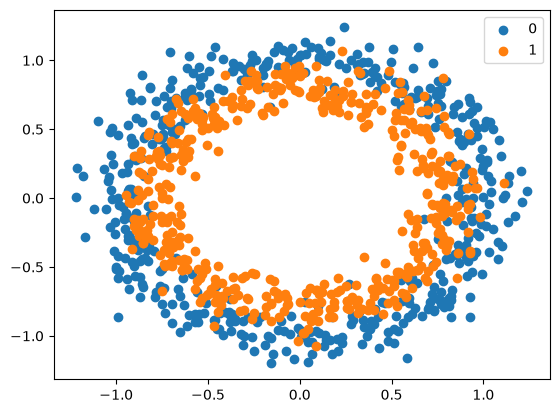

In [20]:
# generación de círculos
# Algunas librerías necesarias
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression, make_circles, make_blobs
from sklearn.preprocessing import StandardScaler
from tensorflow import keras

X, y = make_circles(n_samples=1000, noise=0.1, random_state=1)

plt.scatter(X[np.where((y==0)),0],X[np.where((y==0)),1], label='0')
plt.scatter(X[np.where((y==1)),0],X[np.where((y==1)),1], label='1')
plt.legend()
plt.show()

In [21]:
# Creación del modelo
def build_model2(activation = 'sigmoid', loss='binary_crossentropy'):
  model = keras.models.Sequential()
  model.add(keras.layers.Dense(4, input_dim=2, activation='relu'))
  model.add(keras.layers.Dense(8, activation='relu'))
  model.add(keras.layers.Dense(1, activation = activation))
  opt = keras.optimizers.SGD(learning_rate=0.01)
  model.compile(loss=loss, optimizer=opt, metrics=['accuracy'])
  return model

#https://developers.google.com/machine-learning/crash-course/classification/accuracy#:~:text=Accuracy%20is%20one%20metric%20for,predictions%20Total%20number%20of%20predictions

In [22]:
# [Añadido]
# El ejemplo del enunciado no fija semilla: sin esta línea sus cifras cambian en cada ejecución
keras.utils.set_random_seed(SEED)

Train: 0.810, Test: 0.818


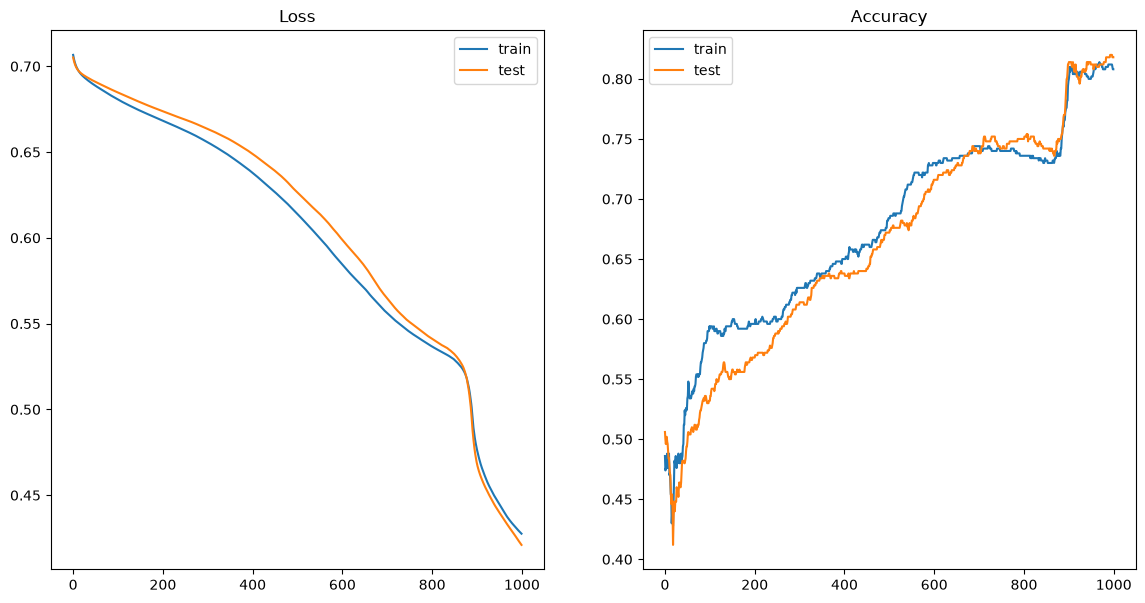

In [23]:
# binary cross entropy:
keras.backend.clear_session()
# Prerprocesado de los datos
n_train = 500
train_X, test_X = X[:n_train, :], X[n_train:, :]
train_y, test_y = y[:n_train], y[n_train:]
model = build_model2()
history = model.fit(train_X, train_y, validation_data=(test_X, test_y), epochs=1000, verbose=0)
# Evaluación del modelo
_, train_acc = model.evaluate(train_X, train_y, verbose=0)
_, test_acc = model.evaluate(test_X, test_y, verbose=0)
print('Train: %.3f, Test: %.3f' % (train_acc, test_acc))
# Gráficas:
plt.figure(figsize=(14,7))
# Gráfica de pérdidas durante el entrenamiento
plt.subplot(121)
plt.title('Loss')
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='test')
plt.legend()
# Gráfica de las precisión durante el entrenamiento
plt.subplot(122)
plt.title('Accuracy')
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='test')
plt.legend()
plt.show()

**Observaciones sobre el ejemplo de los círculos.** La red 2 → 4 → 8 → 1 con SGD ($\eta = 0.01$)
termina con exactitud de 0.810 en entrenamiento y 0.818 en la otra mitad. Las curvas muestran que
después de 1 000 épocas la pérdida sigue bajando: hay una caída brusca cerca de la época 880,
acompañada de un salto de la exactitud de unos 0.74 a 0.81. Entrenamiento y la otra mitad van juntos,
así que no hay sobreajuste. Lo que hay es un modelo todavía sin converger: con SGD a esa tasa,
1 000 épocas no bastan.

Dos detalles del código:

- La mitad de los datos que se pasa como `validation_data` se llama "test" en las gráficas, pero como se
  mira durante el entrenamiento ya no es una prueba independiente. En los puntos del laboratorio se
  separan validación (para decidir) y prueba (para el informe final).
- El ejemplo no fijaba semilla. La celda añadida antes del entrenamiento lo hace, para que las cifras de
  este texto no cambien entre ejecuciones.

# Laboratorio
1. Para el dataset make a moon de sklearn, construir un modelo de una red neuronal con keras para clasificar los datos.

2. Para el dataset load digits, construir un modelo de red neuronal empleando keras para realizar la clasificación.

### Punto 1. Clasificación de `make_moons`

**Plan.**

1. Generar 1 000 puntos de dos medias lunas entrelazadas con ruido gaussiano de desviación 0.2
   (`noise=0.2`). Con ese ruido las clases se solapan un poco, así que no se espera un 100 % de
   exactitud.
2. Partir los datos en 60 % entrenamiento, 20 % validación y 20 % prueba, estratificando por clase.
   Estandarizar con las medias y desviaciones del entrenamiento.
3. Ajustar una regresión logística como referencia. Su frontera es una recta, y las lunas no son
   separables por una recta.
4. Comparar tres arquitecturas en validación, con parada temprana sobre la pérdida de validación.
5. Evaluar en prueba una sola vez, con el modelo elegido y la referencia.

In [24]:
# [Añadido]
import tensorflow as tf
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report
import pandas as pd

EPOCAS_M, PACIENCIA_M = 500, 30     # make_moons: máximo de épocas y paciencia de la parada temprana
EPOCAS_D, PACIENCIA_D = 300, 20     # load_digits
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

TensorFlow 2.22.0-rc0 | Keras 3.15.1


X: (1000, 2) | clases: [500 500]


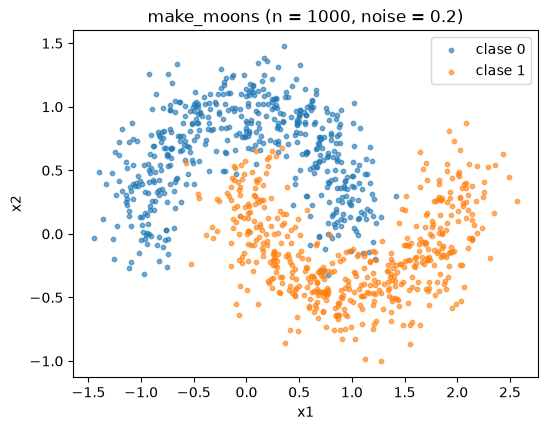

In [25]:
# [Añadido]
X_m, y_m = make_moons(n_samples=1000, noise=0.2, random_state=SEED)
print("X:", X_m.shape, "| clases:", np.bincount(y_m))

plt.figure(figsize=(6, 4.5))
for clase in [0, 1]:
    plt.scatter(X_m[y_m == clase, 0], X_m[y_m == clase, 1], s=10, alpha=0.6, label=f"clase {clase}")
plt.xlabel("x1"); plt.ylabel("x2"); plt.title("make_moons (n = 1000, noise = 0.2)")
plt.legend(); plt.show()

In [26]:
# [Añadido]
# 60 % entrenamiento, 20 % validación, 20 % prueba, estratificado por clase
Xm_tv, Xm_te, ym_tv, ym_te = train_test_split(X_m, y_m, test_size=0.2, stratify=y_m, random_state=SEED)
Xm_tr, Xm_va, ym_tr, ym_va = train_test_split(Xm_tv, ym_tv, test_size=0.25, stratify=ym_tv, random_state=SEED)

escalador_m = StandardScaler().fit(Xm_tr)          # medias y desviaciones solo del entrenamiento
Xm_tr_s, Xm_va_s, Xm_te_s = (escalador_m.transform(A) for A in (Xm_tr, Xm_va, Xm_te))
for nombre, yy in [("entrenamiento", ym_tr), ("validación", ym_va), ("prueba", ym_te)]:
    print(f"{nombre:14s} {len(yy):4d} filas, clase 1: {yy.mean():.1%}")

entrenamiento   600 filas, clase 1: 50.0%
validación      200 filas, clase 1: 50.0%
prueba          200 filas, clase 1: 50.0%


In [27]:
# [Añadido]
# Referencia: regresión logística (frontera lineal)
logreg_m = LogisticRegression().fit(Xm_tr_s, ym_tr)
print(f"Regresión logística  -> exactitud train = {logreg_m.score(Xm_tr_s, ym_tr):.3f}, "
      f"validación = {logreg_m.score(Xm_va_s, ym_va):.3f}")

Regresión logística  -> exactitud train = 0.865, validación = 0.825


**Modelo.** Capas ocultas densas con relu y una salida de 1 neurona sigmoide, que da
$P(y = 1 \mid x)$, con pérdida de entropía cruzada binaria: es la combinación de la sección
"Arquitectura y funcionalidad" para clasificación binaria. Optimizador Adam con tasa 0.01, lotes de 32 y
hasta 500 épocas con parada temprana: se detiene tras 30 épocas sin que `val_loss` mejore al menos
0.001, y se usan los pesos de la mejor época. Se comparan tres tamaños: 1 capa de 4 neuronas, 2 de 16
y 3 de 64. Se elige el de menor pérdida de validación, más fina que la exactitud: con 200 puntos de
validación la exactitud solo se mueve de a 0.5 puntos.

In [28]:
# [Añadido]
def red_moons(capas, lr=0.01):
    modelo = keras.models.Sequential([keras.Input(shape=(2,))]
                                     + [keras.layers.Dense(n, activation="relu") for n in capas]
                                     + [keras.layers.Dense(1, activation="sigmoid")])
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy",
                   metrics=["accuracy"])
    return modelo


def entrenar(constructor, X_tr, y_tr, X_va, y_va, epochs, patience, batch_size=32):
    keras.utils.set_random_seed(SEED)              # misma inicialización y mismo orden de lotes
    modelo = constructor()
    # Una mejora de val_loss menor que min_delta no cuenta: evita que mejoras ínfimas alarguen el entrenamiento
    parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, min_delta=1e-3,
                                           restore_best_weights=True)
    historia = modelo.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=epochs, batch_size=batch_size,
                          callbacks=[parada], verbose=0)
    # Se usan siempre los pesos de la época que el callback consideró mejor (Keras no los restaura
    # por sí solo si el entrenamiento llega a `epochs` sin activar la parada)
    modelo.set_weights(parada.best_weights)
    return modelo, historia.history, parada.best_epoch


arquitecturas_m = [(4,), (16, 16), (64, 64, 64)]
resultados_m, filas = {}, []
for capas in arquitecturas_m:
    modelo, hist, mejor = entrenar(lambda: red_moons(capas), Xm_tr_s, ym_tr, Xm_va_s, ym_va,
                                   epochs=EPOCAS_M, patience=PACIENCIA_M)
    resultados_m[capas] = (modelo, hist, mejor)
    filas.append({"capas ocultas": str(capas), "parámetros": modelo.count_params(), "épocas": len(hist["loss"]),
                  "época recuperada": mejor + 1, "val_loss": hist["val_loss"][mejor],
                  "val_accuracy": hist["val_accuracy"][mejor], "train_accuracy": hist["accuracy"][mejor]})
tabla_m = pd.DataFrame(filas)
display(tabla_m.round(4))
capas_m = arquitecturas_m[int(tabla_m.val_loss.idxmin())]
print("Arquitectura elegida (menor val_loss):", capas_m)

,capas ocultas,parámetros,épocas,época recuperada,val_loss,val_accuracy,train_accuracy
0,"(4,)",17,274,244,0.1168,0.950,0.9717
1,"(16, 16)",337,105,75,0.0687,0.975,0.9750
2,"(64, 64, 64)",8577,75,45,0.0760,0.965,0.9767


Arquitectura elegida (menor val_loss): (16, 16)


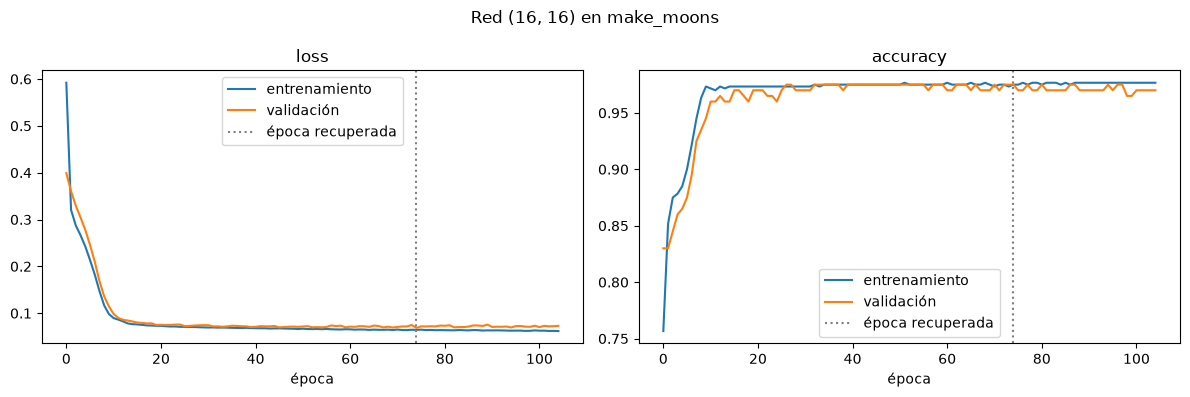

In [29]:
# [Añadido]
modelo_m, hist_m, mejor_m = resultados_m[capas_m]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, clave in zip(axes, ["loss", "accuracy"]):
    ax.plot(hist_m[clave], label="entrenamiento")
    ax.plot(hist_m["val_" + clave], label="validación")
    ax.axvline(mejor_m, color="gray", ls=":", label="época recuperada")
    ax.set(xlabel="época", title=clave)
    ax.legend()
plt.suptitle(f"Red {capas_m} en make_moons")
plt.tight_layout(); plt.show()

**Selección.**

| Capas ocultas | Parámetros | Épocas | Época recuperada | `val_loss` | Exactitud de validación |
|---|---|---|---|---|---|
| (4,) | 17 | 274 | 244 | 0.1168 | 0.950 |
| **(16, 16)** | 337 | 105 | 75 | **0.0687** | **0.975** |
| (64, 64, 64) | 8 577 | 75 | 45 | 0.0760 | 0.965 |

- Se elige (16, 16), que tiene la menor pérdida y la mayor exactitud de validación.
- La red de 4 neuronas se queda corta: su frontera tiene poca flexibilidad.
- La de 3 capas de 64, con 25 veces más parámetros, no mejora: su pérdida de validación es algo mayor y
  se detiene antes.
- Las tres superan con claridad a la regresión logística (0.825 en validación).
- En las curvas de la red elegida, la pérdida cae rápido durante unas 15 épocas y después ambas curvas
  quedan casi planas y juntas. No hay una separación que indique sobreajuste; la parada temprana corta
  cuando ya no hay mejoras de al menos 0.001.

In [30]:
# [Añadido]
# Evaluación final en prueba (una sola vez, con el modelo elegido y la referencia)
prob_te = modelo_m.predict(Xm_te_s, verbose=0).ravel()
pred_red = (prob_te > 0.5).astype(int)
pred_log = logreg_m.predict(Xm_te_s)
print(f"Exactitud en prueba: red = {np.mean(pred_red == ym_te):.3f}   regresión logística = {np.mean(pred_log == ym_te):.3f}")
print(f"(prueba: {len(ym_te)} puntos; un punto = {1 / len(ym_te):.1%})\n")
print("Matriz de confusión de la red (filas = real, columnas = predicho):")
print(confusion_matrix(ym_te, pred_red))
print("\nMatriz de confusión de la regresión logística:")
print(confusion_matrix(ym_te, pred_log))

Exactitud en prueba: red = 0.985   regresión logística = 0.920
(prueba: 200 puntos; un punto = 0.5%)

Matriz de confusión de la red (filas = real, columnas = predicho):
[[ 97   3]
 [  0 100]]

Matriz de confusión de la regresión logística:
[[95  5]
 [11 89]]


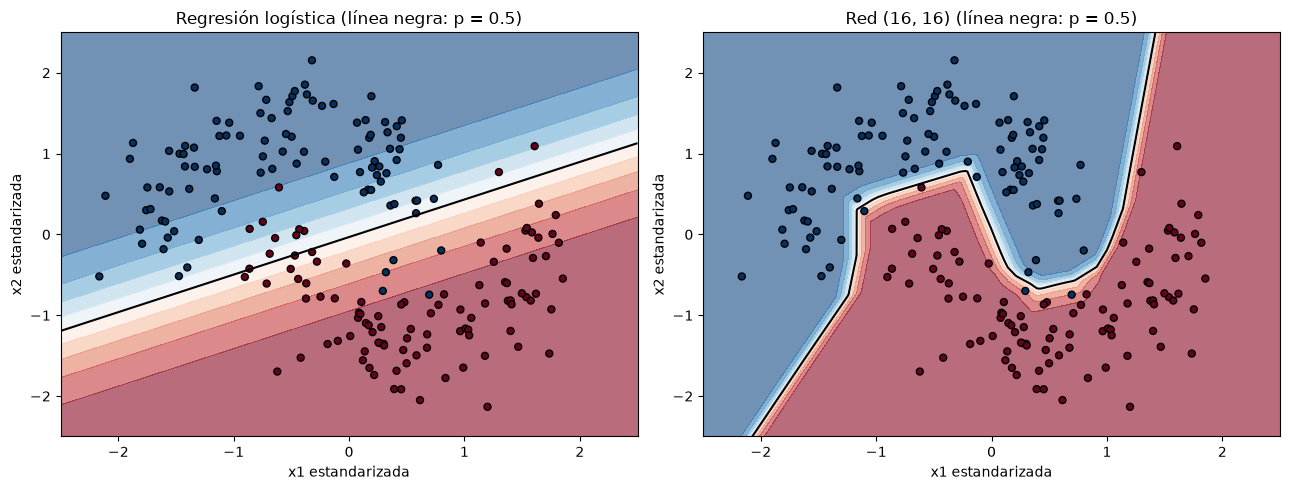

In [31]:
# [Añadido]
# Fronteras de decisión sobre los puntos de prueba
g1, g2 = np.meshgrid(np.linspace(-2.5, 2.5, 300), np.linspace(-2.5, 2.5, 300))
malla = np.c_[g1.ravel(), g2.ravel()]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (titulo, proba) in zip(axes, [
        ("Regresión logística", logreg_m.predict_proba(malla)[:, 1]),
        (f"Red {capas_m}", modelo_m.predict(malla, verbose=0).ravel())]):
    ax.contourf(g1, g2, proba.reshape(g1.shape), levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.6)
    ax.contour(g1, g2, proba.reshape(g1.shape), levels=[0.5], colors="k")
    ax.scatter(Xm_te_s[:, 0], Xm_te_s[:, 1], c=ym_te, cmap="RdBu_r", edgecolor="k", s=25)
    ax.set(title=f"{titulo} (línea negra: p = 0.5)", xlabel="x1 estandarizada", ylabel="x2 estandarizada")
plt.tight_layout(); plt.show()

**Resultado en prueba (200 puntos).**

- **Red (16, 16): 0.985** (197 aciertos). Sus 3 errores son puntos de la clase 0 predichos como 1, y
  acierta los 100 de la clase 1.
- **Regresión logística: 0.920** (184 aciertos, 16 errores repartidos entre las dos clases).

Las fronteras explican la diferencia. La logística solo puede trazar una recta, que corta las
puntas de ambas lunas. La red aprende una frontera curva que sigue la forma de las lunas entre las dos
nubes de puntos. Los errores que quedan están en la zona donde las lunas se tocan; con `noise=0.2`
algunos puntos caen del lado de la otra clase y ningún clasificador puede acertarlos todos.

### Punto 2. Clasificación de `load_digits`

**Plan.** El enunciado ya carga `load_digits(n_class=6)` (imágenes de $8\times8$ de los dígitos 0 a 5,
con 64 píxeles por imagen) y deja la partición `train_test_split(test_size=0.2, random_state=42)`.
Se conserva esa partición tal cual.

1. Separar un 20 % del entrenamiento como validación (estratificado).
2. Llevar los píxeles a $[0, 1]$ dividiendo entre 16, su valor máximo posible.
3. Ajustar una regresión logística multiclase como referencia.
4. Comparar tres redes con salida softmax de 6 neuronas y pérdida
   `sparse_categorical_crossentropy` (las etiquetas son enteros de 0 a 5), con parada temprana.
5. Evaluar en prueba una sola vez.

In [32]:
# Import the necessary modules
import numpy as np
import tensorflow as tf
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits


In [33]:
digits = load_digits(n_class=6)
X, y = digits.data, digits.target
n_samples, n_features = X.shape


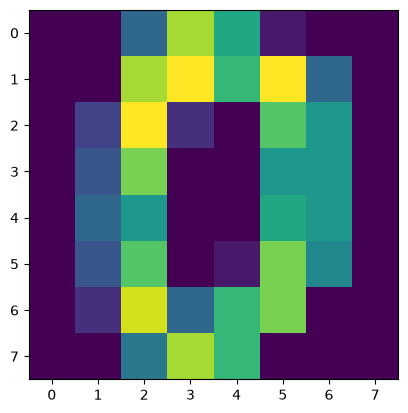

In [34]:
plt.imshow(X[0].reshape(8, 8))

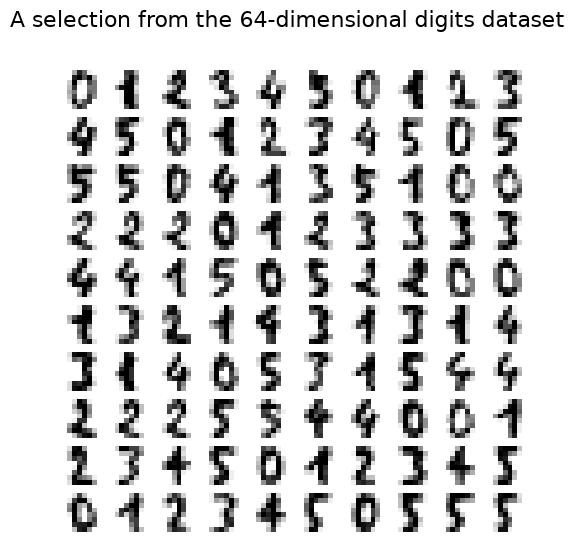

In [35]:
fig, axs = plt.subplots(nrows=10, ncols=10, figsize=(6, 6))
for idx, ax in enumerate(axs.ravel()):
    ax.imshow(X[idx].reshape((8, 8)), cmap=plt.cm.binary)
    ax.axis("off")
_ = fig.suptitle("A selection from the 64-dimensional digits dataset", fontsize=16)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [36]:
# [Añadido]
print("X:", X.shape, "| valores de píxel:", np.unique(X).min(), "a", np.unique(X).max())
print("Clases presentes:", np.unique(y), "| ejemplos por clase:", np.bincount(y))
print("Partición del enunciado -> train:", X_train.shape[0], " test:", X_test.shape[0])
print("Ejemplos por clase en test:", np.bincount(y_test))

X: (1083, 64) | valores de píxel: 0.0 a 16.0
Clases presentes: [0 1 2 3 4 5] | ejemplos por clase: [178 182 177 183 181 182]
Partición del enunciado -> train: 866  test: 217
Ejemplos por clase en test: [39 33 39 40 39 27]


In [37]:
# [Añadido]
# Validación: 20 % del entrenamiento del enunciado, estratificado. El test del enunciado no se toca.
Xd_tr, Xd_va, yd_tr, yd_va = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
# Los píxeles van de 0 a 16 por construcción del dataset: se dividen entre 16 (no depende de los datos)
Xd_tr_s, Xd_va_s, Xd_te_s = Xd_tr / 16, Xd_va / 16, X_test / 16
print("Entrenamiento:", Xd_tr_s.shape, " validación:", Xd_va_s.shape, " prueba:", Xd_te_s.shape)

logreg_d = LogisticRegression(max_iter=5000).fit(Xd_tr_s, yd_tr)
print(f"Regresión logística multiclase -> exactitud train = {logreg_d.score(Xd_tr_s, yd_tr):.3f}, "
      f"validación = {logreg_d.score(Xd_va_s, yd_va):.3f}")

Entrenamiento: (692, 64)  validación: (174, 64)  prueba: (217, 64)
Regresión logística multiclase -> exactitud train = 0.997, validación = 0.966


**Modelo.** Capas ocultas relu y salida softmax de 6 neuronas (una probabilidad por dígito, que suman
1), con pérdida `sparse_categorical_crossentropy`. Optimizador Adam (tasa por defecto, 0.001), lotes de
32 y hasta 300 épocas con parada temprana (paciencia 20, mejora mínima 0.001 en `val_loss`). Se comparan
una capa de 32 neuronas, dos de 64 y 32, y dos de 128 y 64, y se elige la de menor pérdida de validación.

In [38]:
# [Añadido]
def red_digits(capas, n_clases=6):
    modelo = keras.models.Sequential([keras.Input(shape=(64,))]
                                     + [keras.layers.Dense(n, activation="relu") for n in capas]
                                     + [keras.layers.Dense(n_clases, activation="softmax")])
    modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo


arquitecturas_d = [(32,), (64, 32), (128, 64)]
resultados_d, filas = {}, []
for capas in arquitecturas_d:
    modelo, hist, mejor = entrenar(lambda: red_digits(capas), Xd_tr_s, yd_tr, Xd_va_s, yd_va,
                                   epochs=EPOCAS_D, patience=PACIENCIA_D)
    resultados_d[capas] = (modelo, hist, mejor)
    filas.append({"capas ocultas": str(capas), "parámetros": modelo.count_params(), "épocas": len(hist["loss"]),
                  "época recuperada": mejor + 1, "val_loss": hist["val_loss"][mejor],
                  "val_accuracy": hist["val_accuracy"][mejor], "train_accuracy": hist["accuracy"][mejor]})
tabla_d = pd.DataFrame(filas)
display(tabla_d.round(4))
capas_d = arquitecturas_d[int(tabla_d.val_loss.idxmin())]
print("Arquitectura elegida (menor val_loss):", capas_d)

,capas ocultas,parámetros,épocas,época recuperada,val_loss,val_accuracy,train_accuracy
0,"(32,)",2278,238,218,0.0476,0.9770,1.0
1,"(64, 32)",6438,174,154,0.0216,0.9943,1.0
2,"(128, 64)",16966,137,117,0.0278,0.9885,1.0


Arquitectura elegida (menor val_loss): (64, 32)


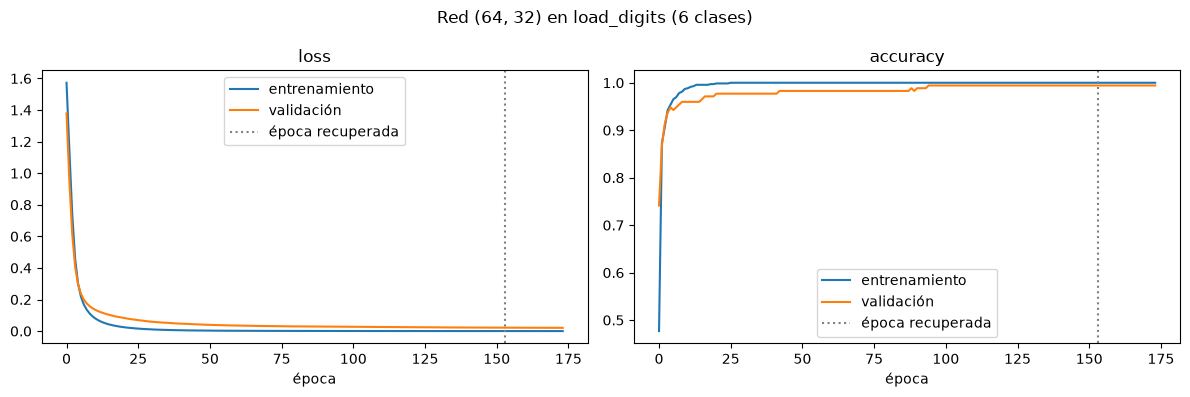

In [39]:
# [Añadido]
modelo_d, hist_d, mejor_d = resultados_d[capas_d]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, clave in zip(axes, ["loss", "accuracy"]):
    ax.plot(hist_d[clave], label="entrenamiento")
    ax.plot(hist_d["val_" + clave], label="validación")
    ax.axvline(mejor_d, color="gray", ls=":", label="época recuperada")
    ax.set(xlabel="época", title=clave)
    ax.legend()
plt.suptitle(f"Red {capas_d} en load_digits (6 clases)")
plt.tight_layout(); plt.show()

**Selección.**

| Capas ocultas | Parámetros | Épocas | Época recuperada | `val_loss` | Exactitud de validación |
|---|---|---|---|---|---|
| (32,) | 2 278 | 238 | 218 | 0.0476 | 0.9770 (170/174) |
| **(64, 32)** | 6 438 | 174 | 154 | **0.0216** | **0.9943** (173/174) |
| (128, 64) | 16 966 | 137 | 117 | 0.0278 | 0.9885 (172/174) |

- Se elige (64, 32). Las tres redes llegan a exactitud 1.0 en entrenamiento, y la regresión logística
  queda en 0.966 de validación (168/174).
- Las diferencias entre redes son de 1 a 3 imágenes de validación: la selección es razonable, pero
  frágil.
- En las curvas, la pérdida de entrenamiento llega prácticamente a cero en unas 25 épocas. La de
  validación baja más despacio y se aplana: la red ya clasifica bien todo el entrenamiento y solo gana
  confianza en las predicciones.

In [40]:
# [Añadido]
proba_d = modelo_d.predict(Xd_te_s, verbose=0)
pred_d = proba_d.argmax(axis=1)
print("La salida softmax es una distribución: forma", proba_d.shape,
      "| suma de cada fila entre", proba_d.sum(axis=1).min().round(6), "y", proba_d.sum(axis=1).max().round(6))
print("Ejemplo, primera imagen de prueba (real =", y_test[0], "):", np.round(proba_d[0], 4), "-> predicho", pred_d[0])
print(f"\nExactitud en prueba: red = {np.mean(pred_d == y_test):.4f}   "
      f"regresión logística = {logreg_d.score(Xd_te_s, y_test):.4f}   ({len(y_test)} imágenes)")
print("\nMatriz de confusión de la red (filas = real, columnas = predicho):")
print(confusion_matrix(y_test, pred_d))
print()
print(classification_report(y_test, pred_d, digits=3))

La salida softmax es una distribución: forma (217, 6) | suma de cada fila entre 1.0 y 1.0
Ejemplo, primera imagen de prueba (real = 1 ): [0.000e+00 9.999e-01 0.000e+00 0.000e+00 1.000e-04 0.000e+00] -> predicho 1

Exactitud en prueba: red = 0.9954   regresión logística = 0.9954   (217 imágenes)

Matriz de confusión de la red (filas = real, columnas = predicho):
[[39  0  0  0  0  0]
 [ 0 33  0  0  0  0]
 [ 0  0 39  0  0  0]
 [ 0  0  0 39  0  1]
 [ 0  0  0  0 39  0]
 [ 0  0  0  0  0 27]]

              precision    recall  f1-score   support

           0      1.000     1.000     1.000        39
           1      1.000     1.000     1.000        33
           2      1.000     1.000     1.000        39
           3      1.000     0.975     0.987        40
           4      1.000     1.000     1.000        39
           5      0.964     1.000     0.982        27

    accuracy                          0.995       217
   macro avg      0.994     0.996     0.995       217
weighted avg      0.

Errores de la red en prueba: 1


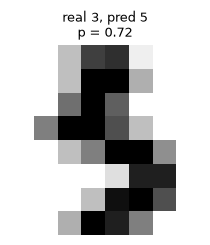

imagen 51: real 3, predicho 5, probabilidades [0.    0.002 0.    0.281 0.    0.716]
Errores de la regresión logística: [51]


In [41]:
# [Añadido]
errores_d = np.where(pred_d != y_test)[0]
print("Errores de la red en prueba:", len(errores_d))
if len(errores_d):
    fig, axes = plt.subplots(1, len(errores_d), figsize=(2.2 * len(errores_d), 2.8), squeeze=False)
    for ax, i in zip(axes[0], errores_d):
        ax.imshow(X_test[i].reshape(8, 8), cmap=plt.cm.binary)
        ax.set_title(f"real {y_test[i]}, pred {pred_d[i]}\np = {proba_d[i, pred_d[i]]:.2f}", fontsize=9)
        ax.axis("off")
    plt.tight_layout(); plt.show()
for i in errores_d:
    print(f"imagen {i}: real {y_test[i]}, predicho {pred_d[i]}, probabilidades {np.round(proba_d[i], 3)}")
print("Errores de la regresión logística:", np.where(logreg_d.predict(Xd_te_s) != y_test)[0])

**Resultado en prueba (217 imágenes).**

- **Red (64, 32): exactitud 0.9954**, un solo error: la imagen 51, un 3 clasificado como 5, con
  probabilidad 0.716 para el 5 y 0.281 para el 3.
- **Regresión logística: exactitud 0.9954**, y su único error es la misma imagen.

La red duda entre las dos clases en lugar de equivocarse con seguridad: después del 5, casi toda la
probabilidad restante va al 3.

Con 6 clases el problema es casi linealmente separable en los 64 píxeles, y **la prueba no permite
distinguir la red de la regresión logística**: ambas cometen el mismo único error. La salida softmax sí
aporta algo práctico, una probabilidad por clase (por ejemplo, 0.9999 para el 1 en la primera imagen de
prueba), que permite detectar los casos dudosos. Por esta razón se añade la extensión de abajo, con un
problema más exigente.

#### Extensión: las 10 clases de `load_digits`

Con 6 clases, la prueba no permite distinguir los modelos (ver la conclusión del punto 2). Como
comprobación adicional, que el enunciado no pide, se repite el procedimiento con los 10 dígitos,
usando la arquitectura ya elegida en el punto 2 sin volver a seleccionarla. La partición y el escalado
siguen la misma receta: 80/20 con `random_state=42` y 20 % del entrenamiento para validación.

In [42]:
# [Añadido]
digits10 = load_digits()                      # sin n_class: los 10 dígitos
X10, y10 = digits10.data / 16, digits10.target
X10_tv, X10_te, y10_tv, y10_te = train_test_split(X10, y10, test_size=0.2, random_state=42)   # como en el enunciado
X10_tr, X10_va, y10_tr, y10_va = train_test_split(X10_tv, y10_tv, test_size=0.2, stratify=y10_tv, random_state=SEED)
print("Imágenes:", X10.shape[0], "| train:", len(y10_tr), " validación:", len(y10_va), " prueba:", len(y10_te))

logreg_10 = LogisticRegression(max_iter=5000).fit(X10_tr, y10_tr)
modelo_10, hist_10, mejor = entrenar(lambda: red_digits(capas_d, n_clases=10), X10_tr, y10_tr, X10_va, y10_va,
                              epochs=EPOCAS_D, patience=PACIENCIA_D)
pred_10 = modelo_10.predict(X10_te, verbose=0).argmax(axis=1)
print(f"Red {capas_d}: {len(hist_10['loss'])} épocas, época recuperada {mejor + 1}")
print(f"Exactitud en validación: red = {hist_10['val_accuracy'][mejor]:.4f}   regresión logística = {logreg_10.score(X10_va, y10_va):.4f}")
print(f"Exactitud en prueba:     red = {np.mean(pred_10 == y10_te):.4f}   regresión logística = {logreg_10.score(X10_te, y10_te):.4f}")
print(f"Errores en prueba: red = {np.sum(pred_10 != y10_te)}   regresión logística = {np.sum(logreg_10.predict(X10_te) != y10_te)}  (de {len(y10_te)})")
print("\nMatriz de confusión de la red (filas = real, columnas = predicho):")
print(confusion_matrix(y10_te, pred_10))

Imágenes: 1797 | train: 1149  validación: 288  prueba: 360


Red (64, 32): 59 épocas, época recuperada 39
Exactitud en validación: red = 0.9514   regresión logística = 0.9618
Exactitud en prueba:     red = 0.9722   regresión logística = 0.9639
Errores en prueba: red = 10   regresión logística = 13  (de 360)

Matriz de confusión de la red (filas = real, columnas = predicho):
[[32  0  0  0  1  0  0  0  0  0]
 [ 0 28  0  0  0  0  0  0  0  0]
 [ 0  1 32  0  0  0  0  0  0  0]
 [ 0  0  0 33  0  1  0  0  0  0]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  1  0  0 44  1  0  0  1]
 [ 1  0  0  0  0  0 34  0  0  0]
 [ 0  0  0  0  0  0  0 33  0  1]
 [ 0  0  0  0  0  1  0  0 29  0]
 [ 0  0  0  1  0  0  0  0  0 39]]


**Resultado con 10 clases.**

- En prueba la red acierta 0.9722 (10 errores de 360) y la regresión logística 0.9639
  (13 errores).
- En validación el orden es el contrario: red 0.9514 frente a 0.9618 de la logística.

Una diferencia de 3 imágenes de prueba que se invierte en validación **no es evidencia de que la red sea
mejor**: con estos tamaños las dos están al mismo nivel. En la matriz de confusión los errores de la red
están repartidos entre muchos pares de clases, sin una confusión dominante. El problema de 10 clases es
más difícil que el de 6 (unos 97 % frente a 99.5 % de acierto), pero una red densa pequeña y un modelo
lineal siguen rindiendo parecido. Las redes convolucionales del laboratorio 11 aprovechan la estructura
espacial de la imagen, que estos dos modelos ignoran.

## Conclusiones

1. **Activaciones (material de la sesión).** Los parámetros de Keras modifican la forma de cada
   activación: `negative_slope` evita el gradiente nulo de relu para $z<0$, `max_value` la acota y
   `threshold` la desplaza; `alpha` fija el valor al que tiende la elu. La softmax convierte puntajes en
   probabilidades, y con dos clases equivale a la sigmoide.
2. **Formas de definir capas.** Las tres formas del enunciado construyen la misma red cuando están bien
   escritas. Sus pesos son intercambiables y dan la misma salida. La celda de la forma 2 tiene un error
   que deja a `modelB` sin activación y le añade una capa a `modelA`.
3. **Punto 1 (`make_moons`).** Una red (16, 16) con salida sigmoide, elegida por pérdida de validación,
   obtiene 0.985 en prueba frente a 0.920 de la regresión logística. La diferencia se explica por
   la frontera: no lineal en la red, recta en la logística.
4. **Punto 2 (`load_digits`, 6 clases).** La red (64, 32) con salida softmax obtiene 0.9954 en prueba,
   un solo error, el mismo que comete la regresión logística. El problema es demasiado fácil para
   separarlas. Con los 10 dígitos (extensión) ambas quedan entre el 95 y el 97 %, y la diferencia entre ellas no es
   consistente entre validación y prueba.
5. **Metodología.** En los dos puntos, la arquitectura se eligió con un conjunto de validación separado,
   la parada temprana usó esa validación y el conjunto de prueba se evaluó una sola vez al final.

#### Reproducibilidad

In [43]:
# [Añadido]
import sys, sklearn
print("Python", sys.version.split()[0], "| numpy", np.__version__, "| TensorFlow", tf.__version__,
      "| Keras", keras.__version__, "| scikit-learn", sklearn.__version__)

Python 3.14.7 | numpy 2.5.3 | TensorFlow 2.22.0-rc0 | Keras 3.15.1 | scikit-learn 1.9.1


Todas las semillas están fijas: `SEED = 42` para las particiones y `keras.utils.set_random_seed` antes de
cada entrenamiento, incluido el ejemplo de los círculos. Además, TensorFlow trabaja en modo determinista
(`enable_op_determinism`). Con eso, una nueva ejecución completa del notebook reproduce las mismas
cifras. En CPU tarda entre 6 y 7 minutos en este equipo, casi todo en los entrenamientos de Keras.